# Presets

You will build: picture sheets of every ready-made pattern, gradient, filter and marker, to pick from.

Run it from this folder with ``python presets.py``, or open ``presets.ipynb``.

In [1]:
import svgwriter as svg

Patterns are fills: `fill=svg.patterns.stripes(angle=45, gap=6)`. Without a `color=` they follow the theme.

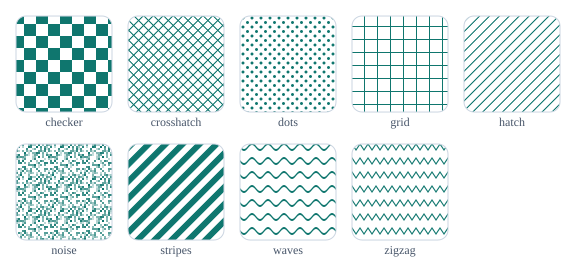

In [2]:
CELL, GAP, LABEL = 96, 16, 16


def sheet(names: list[str], columns: int, background: str = "white") -> tuple[svg.Document, list[tuple[float, float]]]:
    """A document with a labelled cell per name, and the top-left corner of each cell."""
    rows = -(-len(names) // columns)
    width, height = columns * (CELL + GAP) + GAP, rows * (CELL + GAP + LABEL) + GAP
    doc = svg.Document(width, height)
    doc.rect(0, 0, width, height, fill=background)
    corners = []
    for index, name in enumerate(names):
        x = GAP + index % columns * (CELL + GAP)
        y = GAP + index // columns * (CELL + GAP + LABEL)
        doc.text(name, x=x + CELL / 2, y=y + CELL + LABEL - 2, font_size=12, text_anchor="middle", fill="#475569")
        corners.append((x, y))
    return doc, corners


patterns, corners = sheet(svg.patterns.__all__, 5)
for name, (x, y) in zip(svg.patterns.__all__, corners, strict=True):
    patterns.rect(x, y, CELL, CELL, rx=10, fill=getattr(svg.patterns, name)(), stroke="#cbd5e1")
patterns.save("24_patterns.svg")
patterns

Gradients blend colours smoothly, so `blend("red", "blue")` stays vivid through the middle.

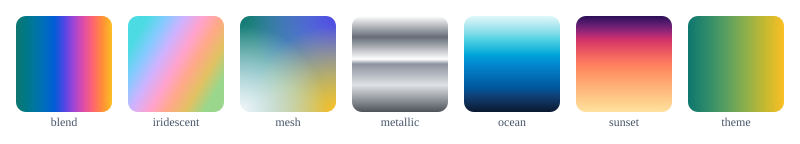

In [3]:
gradients, corners = sheet(svg.gradients.__all__, 7)
for name, (x, y) in zip(svg.gradients.__all__, corners, strict=True):
    gradients.rect(x, y, CELL, CELL, rx=10, fill=getattr(svg.gradients, name)())
gradients.save("24_gradients.svg")
gradients

Filters go straight onto a shape: `card.filter = svg.filters.long_shadow()`.

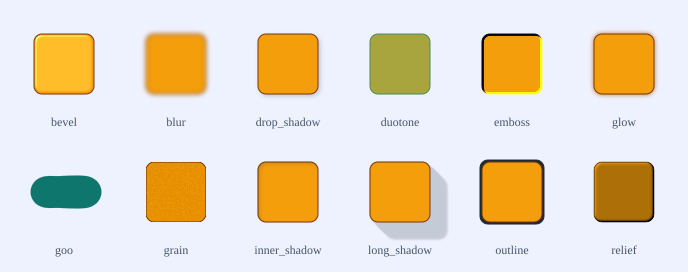

In [4]:
filters, corners = sheet(svg.filters.__all__, 6, background="#eef2ff")
for name, (x, y) in zip(svg.filters.__all__, corners, strict=True):
    if name == "goo":
        with filters.group() as blobs:
            for cx in (x + 30, x + 52, x + 70):
                filters.circle(cx, y + CELL / 2, 15, fill="#0f766e")
        blobs.filter = svg.filters.goo()
        continue
    card = filters.rect(x + 18, y + 18, CELL - 36, CELL - 36, rx=8, fill="#f59e0b", stroke="#78350f")
    card.filter = getattr(svg.filters, name)()
filters.save("24_filters.svg")
filters

Markers go on line ends and corners, and turn with the line. Next: [25 Effects](../25_effects/effects.py).

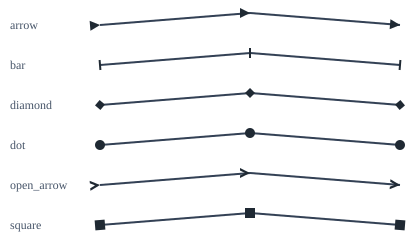

In [5]:
markers = svg.Document(420, 40 * len(svg.markers.__all__) + 10)
for index, name in enumerate(svg.markers.__all__):
    head = getattr(svg.markers, name)()
    y = 25 + index * 40
    markers.text(name, x=10, y=y + 4, font_size=12, fill="#475569")
    markers.path(f"M100 {y} L250 {y - 12} L400 {y}", fill="none", stroke="#334155", stroke_width=2,
                 marker_start=head, marker_mid=head, marker_end=head)
markers.save("24_markers.svg")
markers